# Sesión 33 — Feature Engineering: metodología de selección de variables

**Diplomado en Data Science UC · Facultad de Matemáticas**
Profesor: Eduardo Rodríguez Faúndez

---

## Qué vamos a hacer

Partimos de la base de churn que venimos usando desde la Sesión 30: **3.150 clientes de
una telco y 12 variables**. Al final de este notebook vamos a haber recorrido el embudo
completo de selección de variables y, sobre todo, vamos a haber descubierto que casi
todos los números que calculamos por el camino estaban inflados.

| Bloque | Qué resolvemos | Pregunta que contesta |
|---|---|---|
| 1 | Higiene | ¿Los datos son usables? |
| 2 | Construcción | ¿Tenemos suficientes candidatas? |
| 3 | Diagnóstico | ¿Por qué sobra una variable? |
| 4 | Taxonomía | ¿Qué familias de métodos existen? |
| 5 | Filtros | ¿Cuáles descarto rápido? |
| 6 | Wrapper y embedded | ¿Cuáles quedan al final? |
| 7 | La trampa | ¿Es válido el número que reporté? |

## Notación

A lo largo del notebook usamos:

- $n$ = número de observaciones (3.150 clientes)
- $p$ = número de variables candidatas
- $X_j$ = la variable $j$-ésima
- $Y$ = la variable objetivo `fuga`, con $Y \in \{0, 1\}$
- $\pi = P(Y=1)$ = tasa de fuga de la cartera

---
# Bloque 1 · Higiene: limpiar antes de seleccionar

Ninguna técnica de selección arregla un dato imposible. Si una variable tiene registros
corruptos, su media, su varianza y su correlación con el target están contaminadas, y
cualquier ranking que construyamos sobre ellas va a estar mal.

**El orden importa**: primero se limpia, después se selecciona. Son dos actividades
distintas, con criterios distintos. La limpieza se decide con conocimiento del negocio;
la selección, con estadística.

In [1]:
# --- Carga de datos -------------------------------------------------
# Funciona tanto en Google Colab como en local.
import pandas as pd, numpy as np
import warnings; warnings.filterwarnings("ignore")

RUTA_DRIVE = '/content/drive/My Drive/Clases diplomado UC/2026/churn_telco.csv'
RUTA_LOCAL = 'churn_telco.csv'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    df = pd.read_csv(RUTA_DRIVE)
except Exception:
    df = pd.read_csv(RUTA_LOCAL)

print("Filas y columnas:", df.shape)
print("Tasa de fuga:", round(df.fuga.mean(), 4))
df.head()

Mounted at /content/drive
Filas y columnas: (3150, 13)
Tasa de fuga: 0.1571


,numero_fallas,reclamos,antiguedad,monto,segundos,frec_llamadas,frec_sms,n_contactos,tipo_plan,estado,edad,clv,fuga
0,8,0.0,38.0,0,4370.0,71.0,5.0,17.0,1,1,5,197.640,0
1,0,0.0,39.0,0,NaN,5.0,7.0,4.0,1,1,6,46.035,0
2,10,0.0,37.0,0,2453.0,60.0,359.0,24.0,1,1,2,1536.520,0
3,10,0.0,38.0,0,4198.0,66.0,1.0,35.0,1,1,10,240.020,0
4,3,0.0,NaN,0,2393.0,58.0,2.0,33.0,1,1,9,145.805,0


### Primer diagnóstico

`describe()` entrega los momentos y los cuartiles de cada variable. Lo que buscamos acá
no es entender el negocio todavía, sino **detectar valores imposibles**: mínimos
negativos donde no puede haberlos, máximos absurdos, medias muy separadas de la mediana.

Recordemos qué es cada cosa:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

Y una señal útil: si $\bar{x}$ está muy lejos de la mediana, la variable tiene cola o
tiene basura. La mediana es **robusta** —no se mueve con un outlier— y la media no.

In [2]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
numero_fallas,3150.0,7.63,7.26,0.0,1.00,6.00,12.00,36.00
reclamos,3137.0,0.09,0.28,0.0,0.00,0.00,0.00,1.00
antiguedad,3145.0,32.33,9.35,-40.0,29.00,35.00,38.00,47.00
monto,3150.0,0.94,1.52,0.0,0.00,0.00,1.00,10.00
segundos,3110.0,4453.88,4254.77,-14645.0,1405.75,2996.50,6480.00,17090.00
frec_llamadas,3131.0,69.50,57.80,-176.0,28.00,54.00,95.00,255.00
frec_sms,3146.0,73.26,112.28,-9.0,6.00,21.00,87.75,522.00
n_contactos,3148.0,23.50,17.23,0.0,10.00,21.00,34.00,97.00
tipo_plan,3150.0,1.08,0.27,1.0,1.00,1.00,1.00,2.00
estado,3150.0,1.25,0.43,1.0,1.00,1.00,1.00,2.00


In [3]:
# Nulos declarados. Ojo: que dé cero NO significa que no falten datos.
display(df.isnull().sum().to_frame("nulos"))

,nulos
numero_fallas,0
reclamos,13
antiguedad,5
monto,0
segundos,40
frec_llamadas,19
frec_sms,4
n_contactos,2
tipo_plan,0
estado,0


### Los box plots: dónde están los valores imposibles

Un box plot dibuja la mediana, los cuartiles $Q_1$ y $Q_3$, y marca como atípico todo
punto que caiga fuera de los bigotes:

$$\text{IQR} = Q_3 - Q_1 \qquad \text{atípico si } x < Q_1 - 1{,}5\,\text{IQR} \;\text{ o }\; x > Q_3 + 1{,}5\,\text{IQR}$$

Ese criterio de $1{,}5 \times \text{IQR}$ es una convención, no una ley: viene de que en
una normal deja fuera aproximadamente el 0,7 % de los datos.

**Cuidado con la confusión más común**: un atípico *no* es lo mismo que un error. Un
cliente que habla 17.090 segundos es atípico pero posible. Uno que habla −14.645
segundos es imposible. El box plot los muestra a los dos igual; distinguirlos es trabajo
del analista.

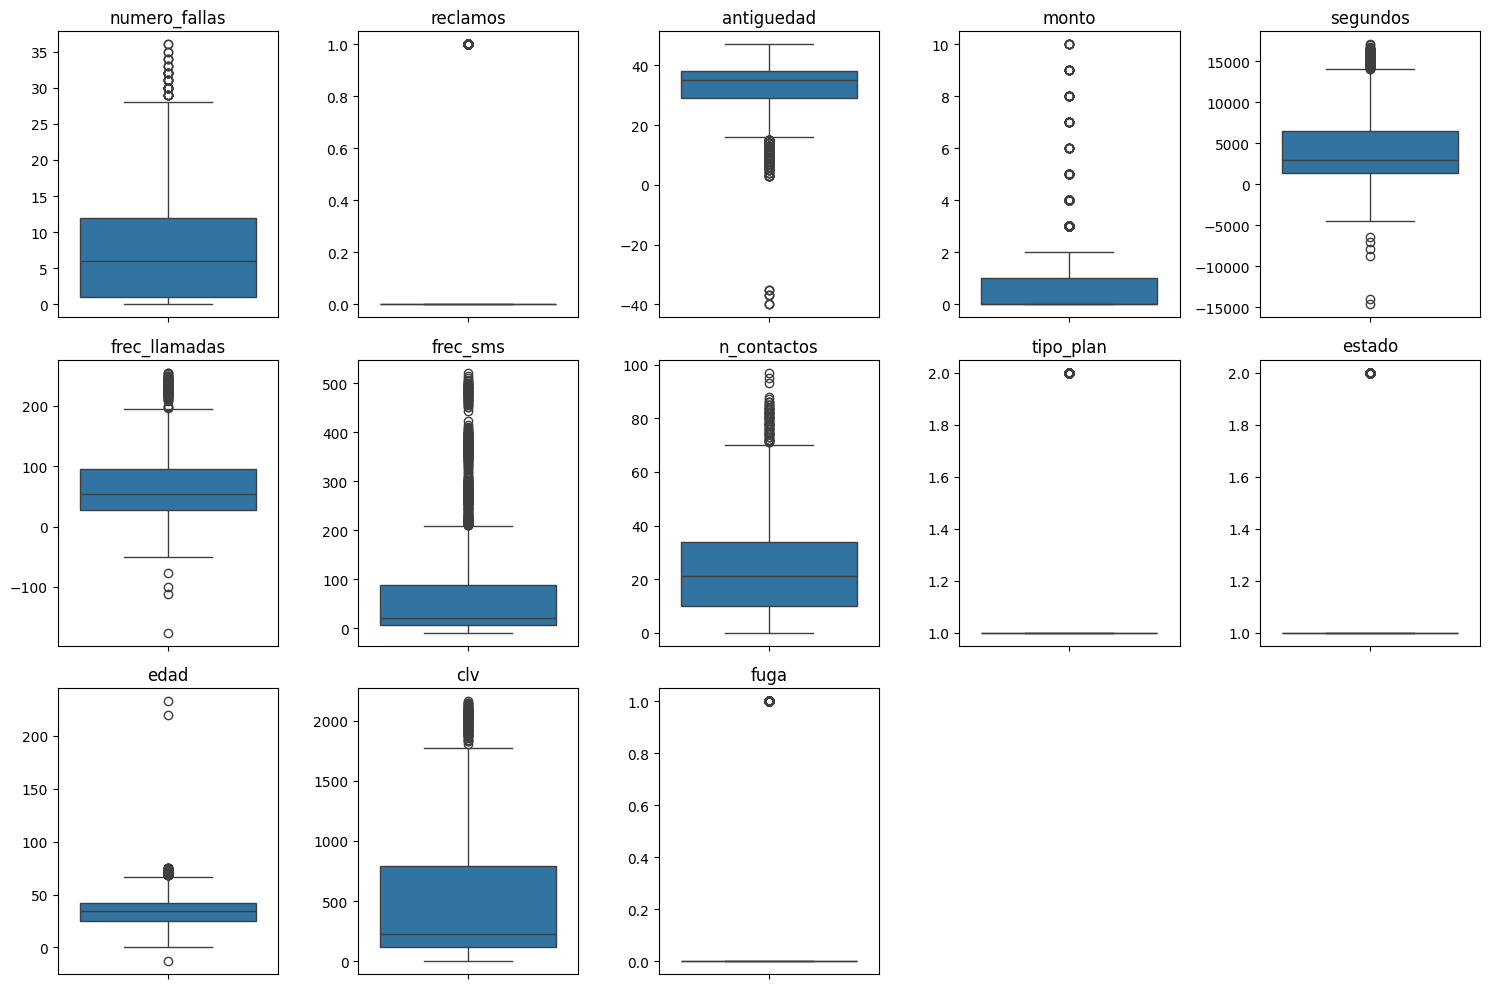

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 5, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [5]:
# ¿Cuántos valores son directamente imposibles?
print("Valores negativos donde no puede haberlos:")
for c in ["segundos", "frec_llamadas", "frec_sms", "antiguedad", "n_contactos"]:
    n = int((df[c] < 0).sum())
    if n:
        print(f"  {c:15s} {n:3d} casos   mínimo: {df[c].min():.0f}")

print("\nEdad — desglose de lo que queda fuera del rango [15, 100]:")
print(f"  negativas          : {int((df.edad < 0).sum()):3d}   mínimo: {df.edad.min():.0f}")
print(f"  entre 0 y 14 años  : {int(((df.edad >= 0) & (df.edad < 15)).sum()):3d}")
print(f"  mayores de 100     : {int((df.edad > 100).sum()):3d}   máximo: {df.edad.max():.0f}")
print(f"  TOTAL              : {int(((df.edad < 15) | (df.edad > 100)).sum()):3d}")

Valores negativos donde no puede haberlos:
  segundos         18 casos   mínimo: -14645
  frec_llamadas    12 casos   mínimo: -176
  frec_sms          1 casos   mínimo: -9
  antiguedad        9 casos   mínimo: -40

Edad — desglose de lo que queda fuera del rango [15, 100]:
  negativas          :   1   mínimo: -13
  entre 0 y 14 años  : 108
  mayores de 100     :   2   máximo: 233
  TOTAL              : 111


### La limpieza

Dos decisiones, y ninguna de las dos es estadística:

1. **Qué es imposible.** Un negativo en `segundos` o en `antiguedad` no existe: es un
   error de captura o de carga. Lo convertimos en `NaN` porque *no sabemos* el valor
   real; poner un cero sería inventar.

2. **Qué rango es admisible.** El umbral de edad entre 15 y 100 años no sale de los
   datos: sale de saber que una telco no contrata a un cliente de 233 años.

   Y acá hay un juicio que conviene discutir en clase. Los casos claramente imposibles
   son solo tres: una edad negativa y dos sobre 100. Pero el rango $[15, 100]$ descarta
   además **108 clientes con edad entre 0 y 14 años**, que son el 3,4 % de la cartera.
   ¿Son errores de carga, o son planes contratados a nombre de un menor? El dato no lo
   dice. Si son lo segundo, estamos borrando un segmento real.

   Esta es exactamente la clase de decisión que **no se resuelve con estadística**: hay
   que preguntarle al dueño del proceso. Mientras tanto, dejarla documentada.

Después imputamos por **mediana** y no por media, justamente porque la mediana no se
deja arrastrar por las colas que acabamos de ver en los box plots.

In [6]:
# 1. Un negativo acá es imposible por definición
for c in ["segundos", "frec_llamadas", "frec_sms", "antiguedad", "n_contactos"]:
    df.loc[df[c] < 0, c] = np.nan

# 2. Rango admisible por criterio de negocio
df.loc[(df.edad < 15) | (df.edad > 100), "edad"] = np.nan

# 3. Imputación por mediana (robusta a las colas)
for c in df.columns:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())

print("Después de limpiar:", df.shape, "| tasa de fuga:", round(df.fuga.mean(), 3))
print("Nulos restantes:", int(df.isna().sum().sum()))

Después de limpiar: (3150, 13) | tasa de fuga: 0.157
Nulos restantes: 0


---
# Bloque 2 · De 12 a 50 variables: fabricar el problema

Con 12 columnas no hay nada que seleccionar. El problema real de selección aparece
cuando hay 50, 200 o 2.000 candidatas y hay que **justificar cada descarte**.

En la Sesión 32 construyeron tres variables derivadas. Acá aplicamos la misma lógica de
forma sistemática, con seis familias de transformaciones.

| Familia | Cuántas | Para qué sirve |
|---|---|---|
| Originales que se conservan | 10 | Punto de partida |
| Ratios | 13 | Normalizar por exposición |
| Interacciones | 3 | Efectos que solo existen combinados |
| Logaritmos | 5 | Comprimir colas largas |
| Indicadores binarios | 5 | Capturar umbrales |
| Discretización en cuartiles | 12 | Capturar no linealidad |
| One-hot | 2 | Codificar categóricas |
| **Total** | **50** | |

Son 12 originales, pero `tipo_plan` y `estado` desaparecen al reemplazarlas por sus
indicadores. Por eso quedan 50 y no 52.

## Por qué cada transformación

**Ratios.** Un cliente con 5.000 segundos de llamadas puede ser alguien que hace muchas
llamadas cortas o pocas llamadas largas. El total no distingue esos dos comportamientos;
el ratio sí:

$$\text{duración promedio} = \frac{\text{segundos}}{\text{frec\_llamadas} + \varepsilon}$$

El $\varepsilon = 10^{-6}$ evita la división por cero. Parece un detalle, pero un solo
infinito rompe todo el pipeline que viene después.

**Interacciones.** Un producto $X_j \cdot X_k$ permite que el efecto de una variable
dependa del valor de la otra. Sin él, un modelo lineal impone que el efecto de
`numero_fallas` sea el mismo para quien reclamó y para quien no.

**Logaritmos.** Usamos $\log(1+x)$ y no $\log(x)$ porque hay ceros en los datos:

$$\text{log1p}(x) = \ln(1 + x), \qquad x \geq 0$$

Comprime las colas: la diferencia entre 10 y 100 pasa a ser del mismo tamaño que entre
100 y 1.000. Eso ayuda a los modelos lineales, que de otro modo quedan dominados por los
valores extremos.

**Indicadores y cuartiles.** Un modelo lineal supone que el efecto de una variable es
constante en todo su rango. Discretizar en cuartiles rompe ese supuesto: cada tramo
recibe su propio coeficiente, y así se pueden capturar relaciones en U o con umbral.

In [7]:
e = 1e-6
d = df.copy()

# --- 1. RATIOS: normalizan una magnitud por su exposición ------------
pares = [
  ("duracion_prom_llamada", "segundos",      "frec_llamadas"),
  ("sms_por_llamada",       "frec_sms",      "frec_llamadas"),
  ("intensidad_contacto",   "n_contactos",   "frec_llamadas"),
  ("segundos_por_contacto", "segundos",      "n_contactos"),
  ("monto_por_llamada",     "monto",         "frec_llamadas"),
  ("clv_por_llamada",       "clv",           "frec_llamadas"),
  ("clv_por_segundo",       "clv",           "segundos"),
  ("sms_por_antiguedad",    "frec_sms",      "antiguedad"),
  ("clv_por_antiguedad",    "clv",           "antiguedad"),
  ("llamadas_por_mes",      "frec_llamadas", "antiguedad"),
  ("contactos_por_mes",     "n_contactos",   "antiguedad"),
  ("fallas_por_antiguedad", "numero_fallas", "antiguedad"),
  ("antiguedad_rel_edad",   "antiguedad",    "edad"),
]
for nom, a, b in pares:
    d[nom] = d[a] / (d[b] + e)

# --- 2. INTERACCIONES: efectos que solo existen combinados -----------
d["reclamo_x_fallas"]   = d.reclamos * d.numero_fallas
d["reclamo_x_antig"]    = d.reclamos * d.antiguedad
d["fallas_x_contactos"] = d.numero_fallas * d.n_contactos

# --- 3. LOGARITMOS: comprimen colas largas ---------------------------
for c in ["segundos", "clv", "frec_sms", "frec_llamadas", "n_contactos"]:
    d[f"log_{c}"] = np.log1p(d[c].clip(lower=0))

# --- 4. INDICADORES BINARIOS: capturan umbrales ----------------------
med = d.segundos.median()
p75 = d.clv.quantile(0.75)
d["tiene_reclamo"] = (d.reclamos > 0).astype(int)
d["sin_sms"]       = (d.frec_sms == 0).astype(int)
d["uso_alto"]      = (d.segundos > med).astype(int)
d["clv_alto"]      = (d.clv > p75).astype(int)
d["cliente_nuevo"] = (d.antiguedad < 12).astype(int)

# --- 5. DISCRETIZACIÓN EN CUARTILES: captura no linealidad -----------
for col in ["edad", "antiguedad", "clv"]:
    q = pd.qcut(d[col], 4, labels=False, duplicates="drop")
    for k in sorted(q.dropna().unique()):
        d[f"{col}_q{int(k)+1}"] = (q == k).astype(int)

# --- 6. ONE-HOT: las categóricas originales se van -------------------
d["plan_2"]   = (d.tipo_plan == 2).astype(int)
d["estado_2"] = (d.estado == 2).astype(int)
d = d.drop(columns=["tipo_plan", "estado"])

X = d.drop(columns="fuga")
y = d["fuga"]
print("Candidatas:", X.shape[1], "  observaciones:", X.shape[0])

Candidatas: 50   observaciones: 3150


---
# Bloque 3 · Irrelevante, redundante y relevante solo en conjunto

Una variable puede sobrar por tres motivos distintos, y **cada uno pide una decisión
distinta**. Confundirlos es la fuente de error más común en selección de variables.

| Tipo | Qué pasa | Qué hacer |
|---|---|---|
| **Irrelevante** | No aporta información sobre el target, ni sola ni acompañada | Se descarta |
| **Redundante** | Aporta, pero su información ya está en otra variable | Se conserva una de las dos |
| **Relevante solo en conjunto** | Sola parece ruido; combinada con otra, aporta | **Los filtros univariados la matan** |

## La herramienta básica: correlación de Pearson

$$r_{XY} = \frac{\operatorname{Cov}(X,Y)}{\sigma_X \, \sigma_Y} = \frac{\sum_{i}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i}(x_i - \bar{x})^2} \, \sqrt{\sum_{i}(y_i - \bar{y})^2}}$$

Con $r \in [-1, 1]$. Pero tiene una limitación que hay que tener siempre presente:
**mide solo relación lineal**. Si $Y$ depende de $X$ en forma de U, la correlación puede
dar exactamente cero aunque la dependencia sea perfecta.

In [8]:
# Correlación de cada variable ORIGINAL con la fuga
originales = ["numero_fallas", "reclamos", "antiguedad", "monto", "segundos",
              "frec_llamadas", "frec_sms", "n_contactos", "edad", "clv",
              "plan_2", "estado_2"]
corr_target = d[originales + ["fuga"]].corr()["fuga"].drop("fuga")
display(corr_target.sort_values(key=abs, ascending=False).to_frame("corr con fuga").round(3))

,corr con fuga
reclamos,0.511
estado_2,0.319
frec_llamadas,-0.296
segundos,-0.294
clv,-0.289
n_contactos,-0.279
frec_sms,-0.221
monto,-0.202
plan_2,-0.106
antiguedad,-0.032


### Candidatas a irrelevantes

Tres variables tienen correlación prácticamente nula con la fuga: `numero_fallas`,
`edad` y `antiguedad`. Pero antes de descartarlas hay que verificar con una medida que
capture también relaciones **no** lineales — para eso está la información mutua, que
vemos en el bloque 5.

Guardemos la sospecha y sigamos.

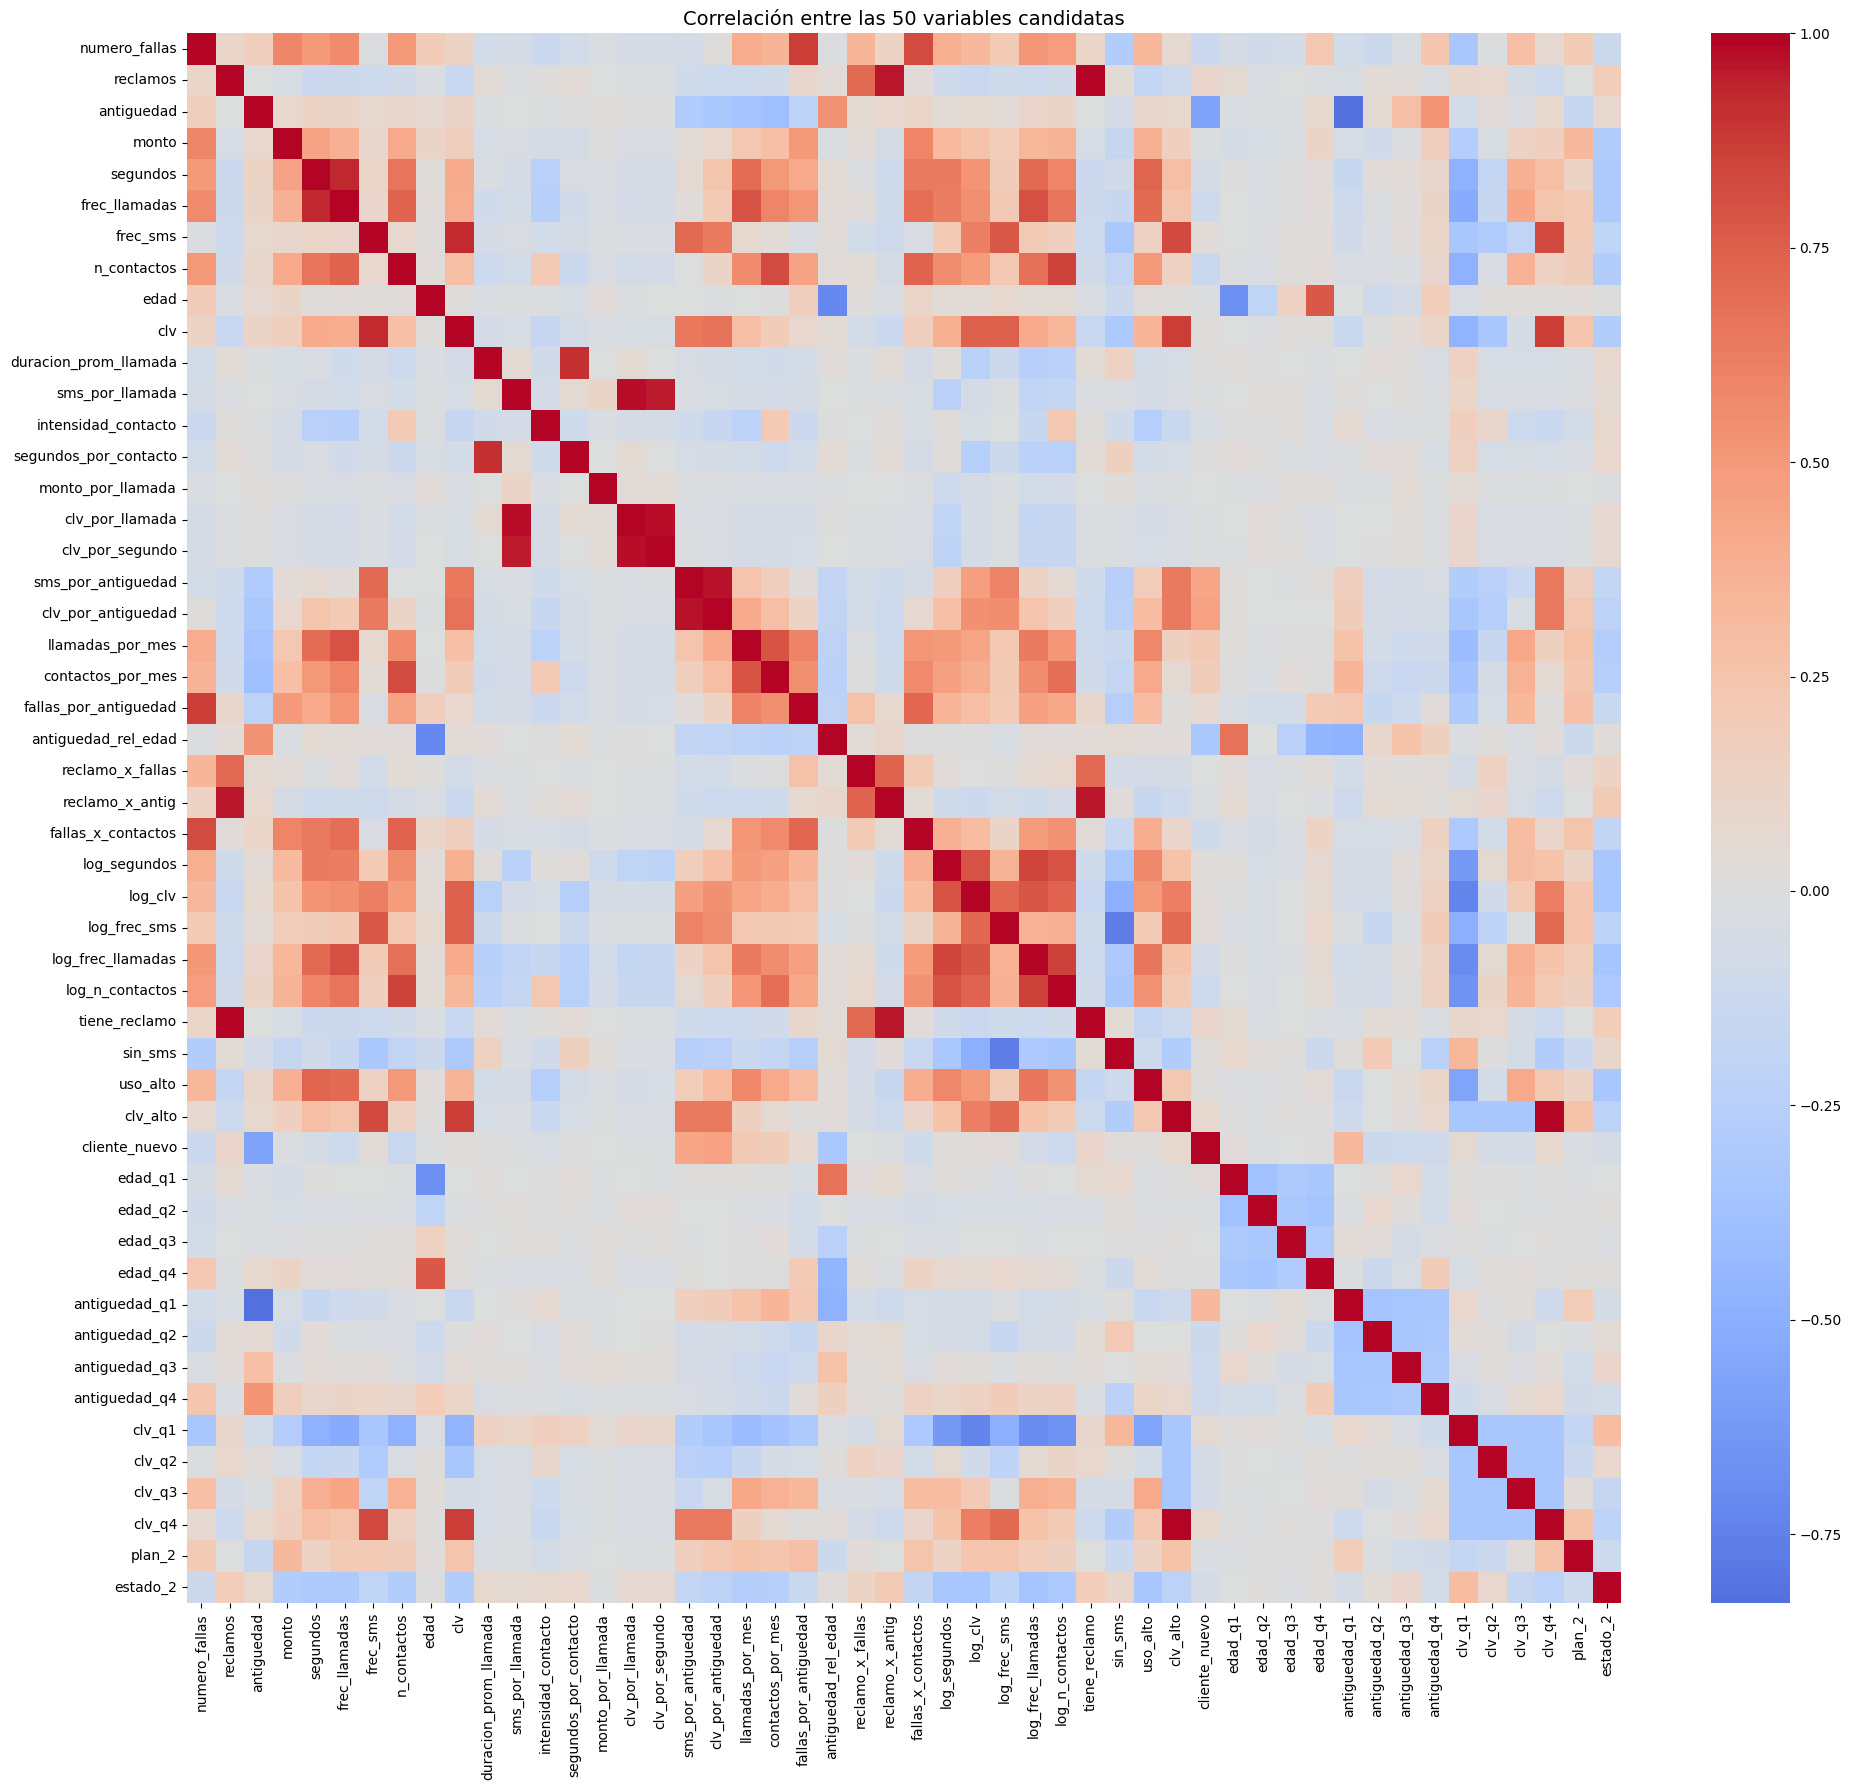

In [9]:
# Matriz de correlación entre las 50 candidatas: buscamos redundancia
correlation_matrix = X.corr()

plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Correlación entre las 50 variables candidatas', fontsize=14)
plt.tight_layout()
plt.show()

Los bloques rojos fuera de la diagonal son grupos de variables que llevan casi la misma
información. Buena parte de esa redundancia **la fabricamos nosotros** en el bloque 2:
`tiene_reclamo` correlaciona 1,000 con `reclamos` porque es la misma información con
otra forma.

Ese es un punto que conviene subrayar: **crear variables sin después seleccionar no
mejora el modelo, lo infla.**

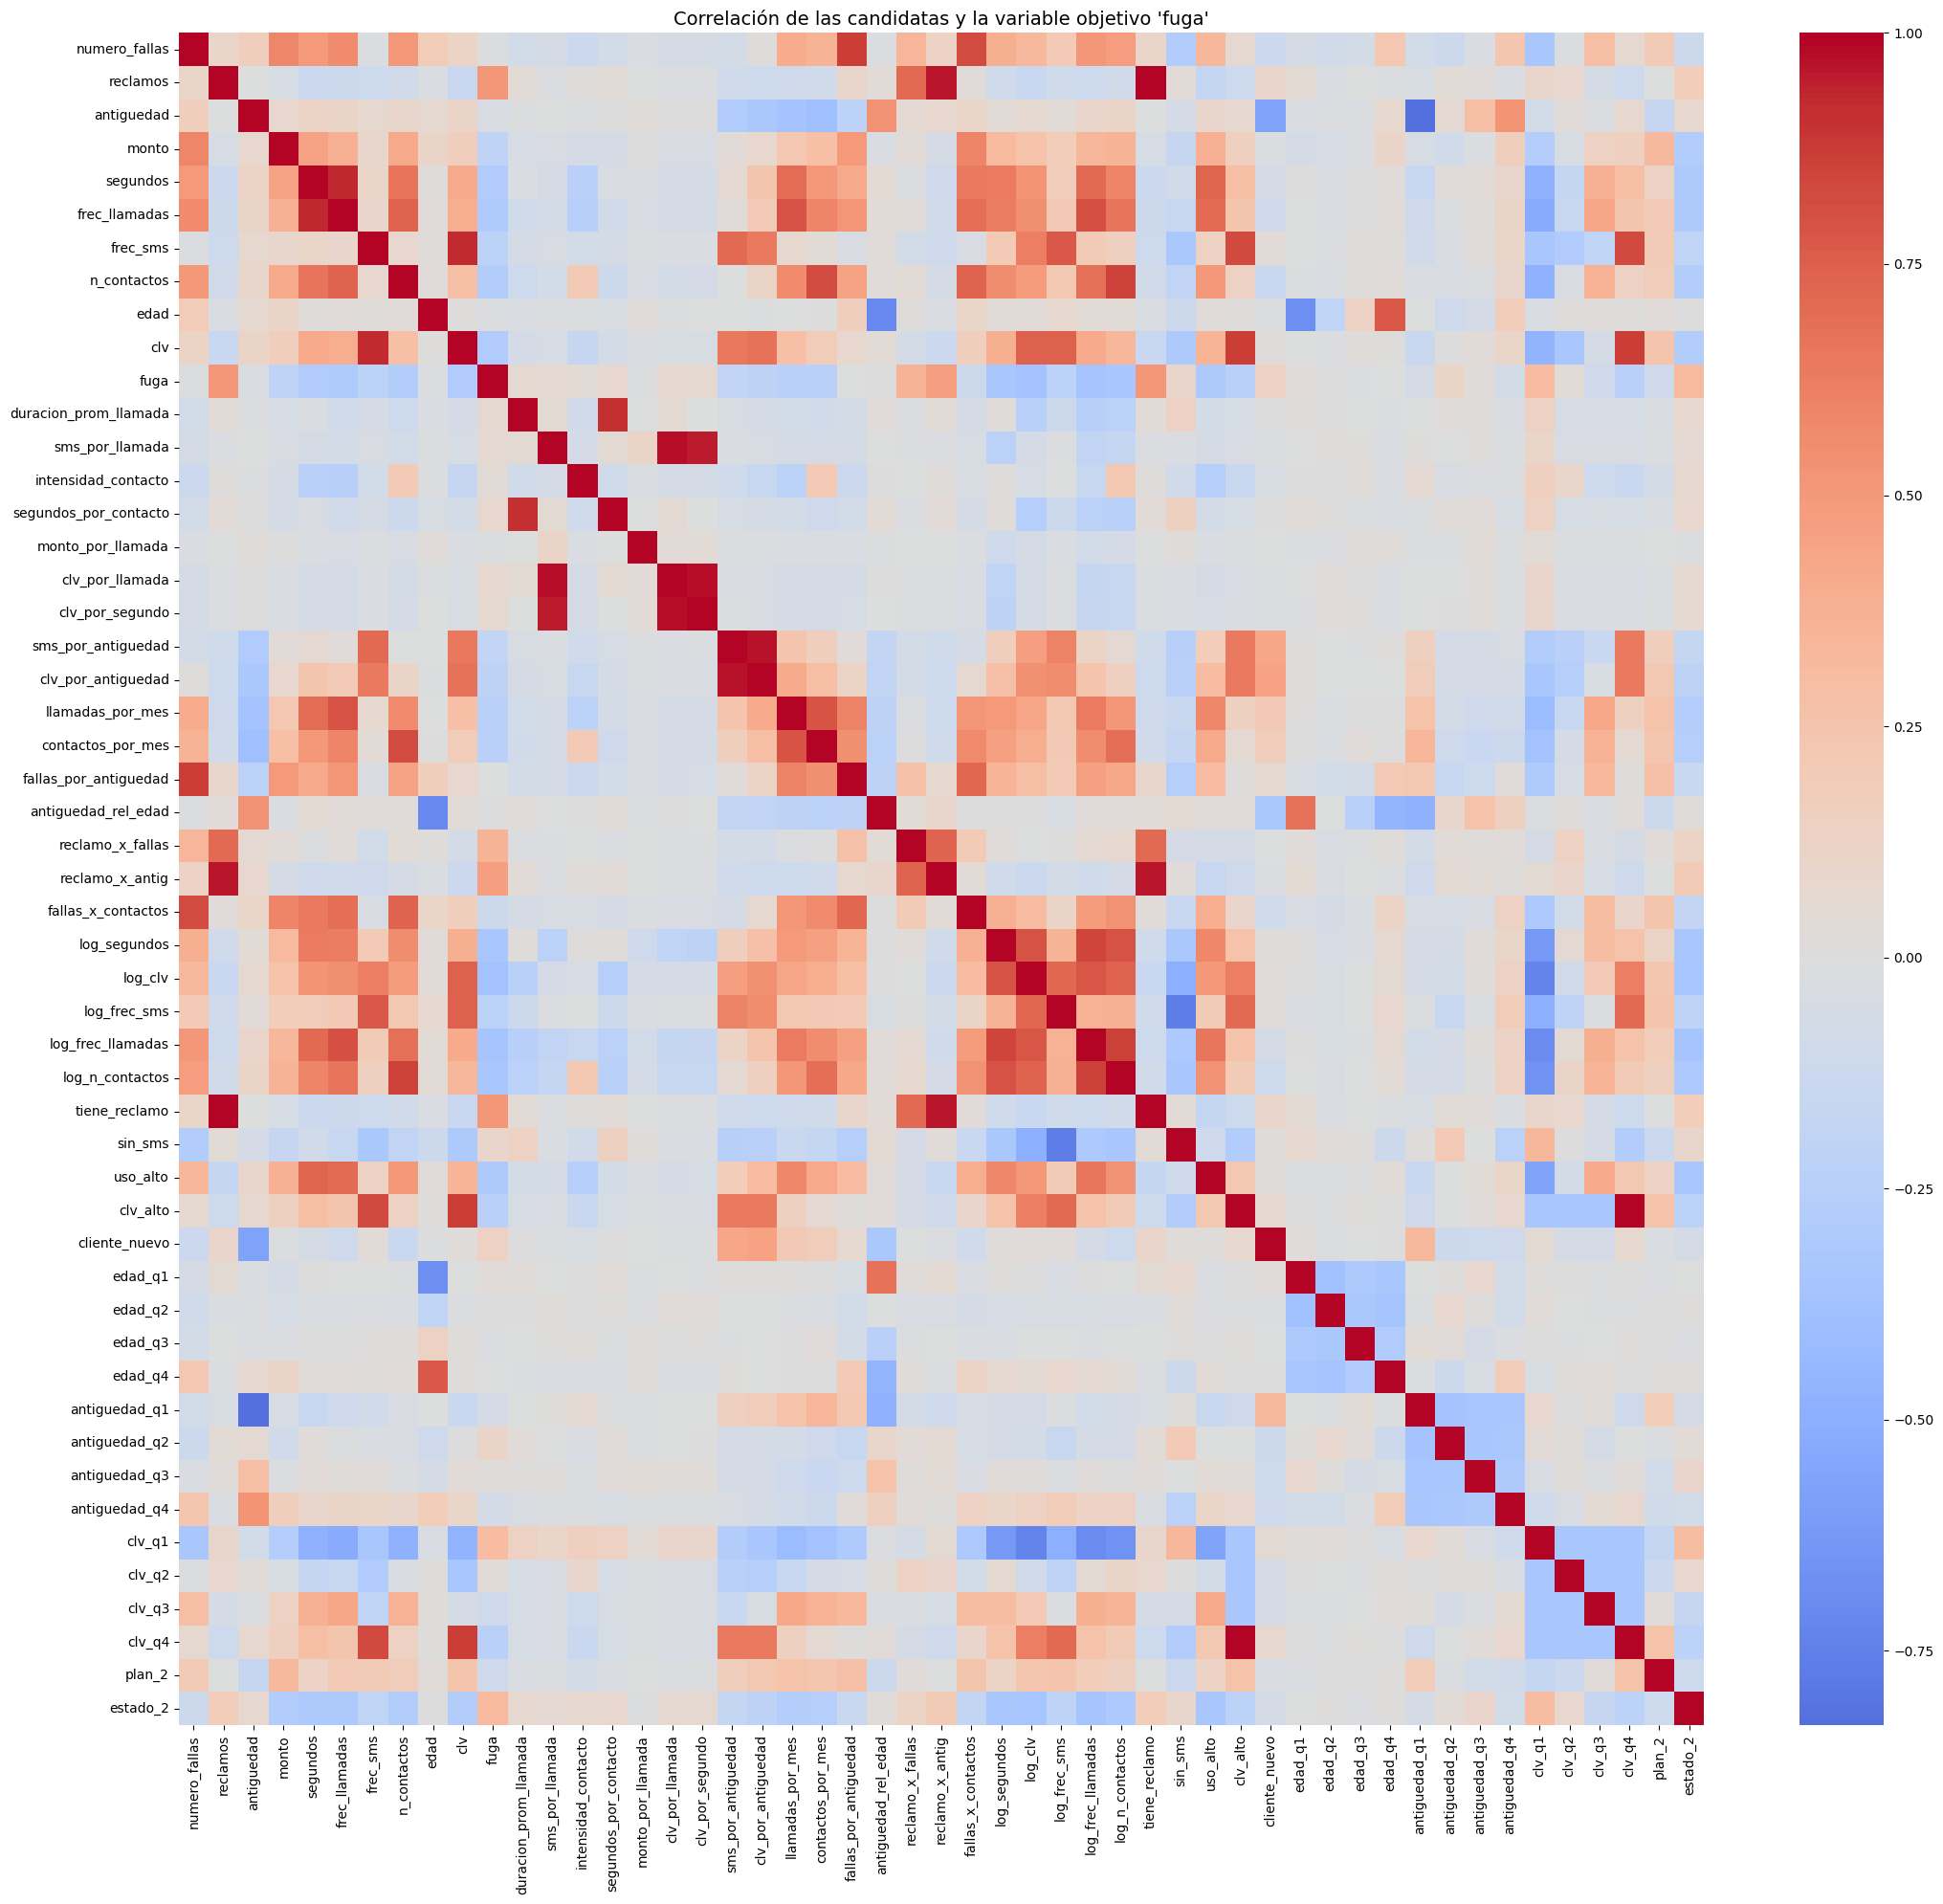

In [10]:
# Correlación incluyendo el target, para ver qué se relaciona con 'fuga'
plt.figure(figsize=(22, 20))
sns.heatmap(d.corr(), annot=False, cmap='coolwarm', center=0)
plt.title("Correlación de las candidatas y la variable objetivo 'fuga'", fontsize=14)
plt.tight_layout()
plt.show()

## El caso que rompe los filtros univariados

Antes de aceptar que `numero_fallas` es irrelevante, hagamos la prueba correcta:
medir cuánto aporta **acompañada**, no sola.

Un filtro univariado evalúa $X_j$ contra $Y$ ignorando el resto. Formalmente, ordena por
alguna medida $s(X_j, Y)$ y se queda con las mejores. El problema es que existen
variables donde

$$s(X_j, Y) \approx 0 \qquad \text{pero} \qquad s\big((X_j, X_k), Y\big) \text{ es grande}$$

El caso extremo es el XOR: dos variables independientes del target por separado que
juntas lo predicen perfecto.

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(5, shuffle=True, random_state=1)

def auc(cols):
    # AUC con validación cruzada usando solo las columnas indicadas
    modelo = Pipeline([("sc", StandardScaler()),
                       ("clf", LogisticRegression(max_iter=3000))])
    return cross_val_score(modelo, X[cols], y, cv=cv, scoring="roc_auc").mean()

base = ["reclamos", "segundos", "frec_llamadas", "estado_2", "clv"]

print(f"Solo numero_fallas            : AUC {auc(['numero_fallas']):.4f}")
print(f"Base de 5 variables           : AUC {auc(base):.4f}")
print(f"Base + numero_fallas          : AUC {auc(base + ['numero_fallas']):.4f}")
print(f"Base + numero_fallas + monto  : AUC {auc(base + ['numero_fallas', 'monto']):.4f}")

Solo numero_fallas            : AUC 0.5261
Base de 5 variables           : AUC 0.9069
Base + numero_fallas          : AUC 0.9102
Base + numero_fallas + monto  : AUC 0.9171


**Sola da 0,53 —prácticamente azar— y sin embargo mejora el conjunto.**

La conclusión que hay que llevarse: un p-valor alto no significa «esta variable no
sirve». Significa **«esta variable no sirve sola»**. Es el argumento central a favor de
los métodos multivariados, y la razón por la que un ranking univariado nunca debería ser
la última palabra.

In [12]:
# El contraejemplo de laboratorio: XOR
# Dos variables normales independientes; el target es 1 cuando
# exactamente una de las dos es positiva.
from sklearn.feature_selection import f_classif

rng = np.random.default_rng(7)
x1 = rng.normal(size=5000)
x2 = rng.normal(size=5000)
t  = ((x1 > 0) ^ (x2 > 0)).astype(int)

Z  = np.c_[x1, x2]            # solo las dos variables
Zi = np.c_[x1, x2, x1 * x2]   # agregando el término de interacción

F_xor, p_xor = f_classif(Z, t)
print("Lo que ve un filtro univariado (ANOVA F):")
print(f"  x1 -> F = {F_xor[0]:6.3f},  p = {p_xor[0]:.3f}")
print(f"  x2 -> F = {F_xor[1]:6.3f},  p = {p_xor[1]:.3f}")
print("  Veredicto del filtro: 'ninguna de las dos sirve'\n")

print("Lo que pasa según cómo se las mire:")
for nombre, datos in [("Logística con x1 y x2", Z),
                      ("Logística + interacción x1*x2", Zi)]:
    a = cross_val_score(LogisticRegression(max_iter=2000), datos, t,
                        cv=5, scoring="roc_auc").mean()
    print(f"  {nombre:32s} AUC {a:.3f}")

from sklearn.ensemble import RandomForestClassifier
a_rf = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0),
                       Z, t, cv=5, scoring="roc_auc").mean()
print(f"  {'Random Forest (200 árboles)':32s} AUC {a_rf:.3f}")

Lo que ve un filtro univariado (ANOVA F):
  x1 -> F =  1.212,  p = 0.271
  x2 -> F =  4.312,  p = 0.038
  Veredicto del filtro: 'ninguna de las dos sirve'

Lo que pasa según cómo se las mire:
  Logística con x1 y x2            AUC 0.510
  Logística + interacción x1*x2    AUC 1.000
  Random Forest (200 árboles)      AUC 1.000


La logística con las dos variables da 0,51: **no ve nada**. Con el término de
interacción $x_1 \cdot x_2$ agregado, da 1,000. La señal siempre estuvo ahí; lo que
faltaba era una representación que la dejara visible.

Un detalle que conviene mostrar y que suele sorprender: **un árbol de decisión poco
profundo también falla en el XOR**. El algoritmo es voraz y evalúa un corte por vez;
como ningún corte individual reduce la impureza, elige uno arbitrario y puede no
recuperarse. Recién con profundidad 4 o más lo resuelve de forma consistente. Un Random
Forest sí lo logra, porque promedia muchos árboles con distintos cortes iniciales.

Ese es el argumento de fondo a favor de las **interacciones** que construimos en el
bloque 2: si sospechás que dos variables actúan en conjunto, la forma más segura de que
el modelo lo vea es escribir el producto explícitamente.

---
# Bloque 4 · Taxonomía: filter, wrapper, embedded

Todos los métodos de selección caen en una de tres familias. La diferencia está en
**cuándo y cómo consultan al modelo**.

| Familia | Cómo decide | Costo | ¿Ve interacciones? | Ejemplos |
|---|---|---|---|---|
| **Filter** | Con una métrica estadística, sin entrenar el modelo | Bajo | No, si es univariado | Varianza, correlación, información mutua, ANOVA F |
| **Wrapper** | Entrena el modelo con distintos subconjuntos y compara | Alto | Sí | RFE, forward y backward selection |
| **Embedded** | La selección ocurre dentro del entrenamiento | Medio | Sí | Lasso, importancia de árboles |

## El costo, en números

Sea $p$ el número de variables. El costo de cada familia, medido en cantidad de modelos
que hay que entrenar:

$$\text{Filter}: 0 \qquad \text{Embedded}: 1 \qquad \text{RFE con paso 1}: p - k \qquad \text{Búsqueda exhaustiva}: 2^p - 1$$

Con nuestras 50 variables, la búsqueda exhaustiva significaría entrenar
$2^{50} \approx 1{,}1 \times 10^{15}$ modelos. A mil modelos por segundo serían unos
**36.000 años**. Por eso nadie la usa: todos los métodos prácticos son heurísticas.

## Ya conocen un método embedded

La Sesión 31 explicó que «Lasso (L1) puede llevar coeficientes a cero y, en la práctica,
apagar variables poco útiles». Eso es exactamente un método embedded: la selección
ocurre mientras el modelo se entrena.

## Regla práctica de secuencia

No son alternativas entre sí, son **etapas de un mismo embudo**:

$$5.000 \xrightarrow{\ \text{filtro}\ } 200 \xrightarrow{\ \text{embedded}\ } 30 \xrightarrow{\ \text{wrapper}\ } 12$$

In [13]:
# El costo de la búsqueda exhaustiva, para dimensionarlo
p = X.shape[1]
subconjuntos = 2**p - 1
segundos = subconjuntos / 1000            # suponiendo 1.000 modelos por segundo
print(f"Variables: {p}")
print(f"Subconjuntos posibles: {subconjuntos:,}")
print(f"A 1.000 modelos/segundo: {segundos/60/60/24/365:,.0f} años")
print(f"\nRFE con paso 1 hasta 12 variables: {p-12} modelos por fold")

Variables: 50
Subconjuntos posibles: 1,125,899,906,842,623
A 1.000 modelos/segundo: 35,702 años

RFE con paso 1 hasta 12 variables: 38 modelos por fold


---
# Bloque 5 · Métodos de filtro

Rápidos, escalables y con un punto ciego importante. Veamos las tres métricas y qué mide
cada una.

## 1. Varianza casi nula

$$\operatorname{Var}(X_j) = \frac{1}{n}\sum_{i=1}^{n}(x_{ij} - \bar{x}_j)^2$$

Una variable que casi no varía no puede explicar nada, porque toma el mismo valor para
casi todos los clientes.

Para una variable **binaria** con proporción $\pi$ de unos, la varianza tiene forma
cerrada:

$$\operatorname{Var}(X) = \pi(1-\pi)$$

Entonces `threshold=0.01` significa exigir $\pi(1-\pi) > 0{,}01$, lo que se cumple
cuando $\pi \in (0{,}0102,\ 0{,}9898)$. Dicho en castellano: **se descartan las binarias
con menos del 1 % de casos en su categoría minoritaria.**

## 2. Información mutua

Primero la entropía, que mide incertidumbre:

$$H(Y) = -\sum_{k} P(Y=k)\log P(Y=k)$$

La información mutua es cuánta de esa incertidumbre desaparece al conocer $X$:

$$I(X;Y) = H(Y) - H(Y \mid X) = \sum_{x}\sum_{y} p(x,y)\,\log\frac{p(x,y)}{p(x)\,p(y)}$$

Propiedades que importan en la práctica:

- $I(X;Y) \geq 0$, y vale exactamente $0$ si y solo si $X$ e $Y$ son independientes.
- **Detecta cualquier tipo de dependencia**, también las no lineales. Ahí está su ventaja
  sobre la correlación.
- **No tiene techo**: su valor máximo depende de $H(Y)$. Por eso sirve para *ordenar*
  variables dentro de un dataset, pero no para comparar entre datasets distintos.
- Para variables continuas, `scikit-learn` la estima con vecinos más cercanos. Eso
  introduce aleatoriedad: **sin fijar `random_state` el valor cambia en cada corrida.**

## 3. ANOVA F

Compara la dispersión *entre* grupos contra la dispersión *dentro* de cada grupo.

Sea $g$ el número de grupos —acá $g=2$: los que se fugan y los que no—, $G_k$ el
conjunto de observaciones del grupo $k$, $n_k$ su tamaño, $\bar{x}_k$ su media y
$\bar{x}$ la media global. Se definen dos cuadrados medios:

$$\text{MS}_{\text{entre}} = \frac{1}{g-1}\sum_{k=1}^{g} n_k \left(\bar{x}_k - \bar{x}\right)^2$$

$$\text{MS}_{\text{dentro}} = \frac{1}{n-g}\sum_{k=1}^{g} \sum_{i \in G_k} \left(x_i - \bar{x}_k\right)^2$$

Y el estadístico es su cociente:

$$F = \frac{\text{MS}_{\text{entre}}}{\text{MS}_{\text{dentro}}}$$

El numerador mide cuánto se separan las medias de los grupos; el denominador, cuánto
varían los datos dentro de cada grupo. Si $F$ es grande, la separación entre grupos
domina al ruido interno.

**Su punto ciego**: solo mira diferencias de **medias**. Si la relación tiene forma de U,
las medias de los dos grupos pueden coincidir y $F \approx 0$ aunque la señal exista. Es
exactamente lo que le pasó a las variables del XOR.

In [14]:
from sklearn.feature_selection import (
    VarianceThreshold, mutual_info_classif, f_classif)

# --- 1. VARIANZA CASI NULA -------------------------------------------
vt = VarianceThreshold(threshold=0.01).fit(X)
constantes = X.columns[~vt.get_support()]
print("Sin variabilidad útil:", list(constantes) or "ninguna")

# --- 2. INFORMACIÓN MUTUA --------------------------------------------
# random_state fijo: la estimación usa vecinos al azar
mi = pd.Series(mutual_info_classif(X, y, random_state=0), index=X.columns)

# --- 3. ANOVA F ------------------------------------------------------
F, p_val = f_classif(X, y)

rank = pd.DataFrame({"MI": mi, "F": F, "p": p_val})
display(rank.sort_values("MI", ascending=False).head(12).round(4))

Sin variabilidad útil: ninguna


,MI,F,p
segundos,0.1315,297.1800,0.0000
log_segundos,0.1285,419.0488,0.0000
contactos_por_mes,0.1078,176.7979,0.0000
log_clv,0.1052,496.0195,0.0000
clv_por_antiguedad,0.1031,150.0142,0.0000
tiene_reclamo,0.1023,1115.0755,0.0000
clv,0.1018,287.1976,0.0000
llamadas_por_mes,0.0987,187.9515,0.0000
reclamo_x_antig,0.0962,872.3754,0.0000
intensidad_contacto,0.0946,5.8827,0.0153


In [15]:
# ¿Confirma la información mutua la sospecha del bloque 3?
sospechosas = ["numero_fallas", "edad", "antiguedad", "reclamos"]
display(rank.loc[sospechosas].round(4))

,MI,F,p
numero_fallas,0.0000,0.2717,0.6022
edad,0.0000,1.0889,0.2968
antiguedad,0.0240,3.2528,0.0714
reclamos,0.0836,1115.0755,0.0000


`numero_fallas` y `edad` dan información mutua nula y p-valor alto: **para un filtro
univariado son ruido**. Y sin embargo ya comprobamos que `numero_fallas` mejora el
modelo cuando se la acompaña. El filtro no está equivocado, está mirando otra cosa.

## Redundancia entre candidatas

La matriz de correlación es simétrica y tiene 1 en la diagonal, así que dos de cada tres
celdas sobran. Para recorrer cada par **una sola vez** nos quedamos con el triángulo
superior:

$$\text{quedarse con } r_{jk} \text{ solo si } j < k$$

Eso es exactamente lo que hace `np.triu(..., k=1)`.

In [16]:
# La matriz de correlación es simétrica: nos basta el triángulo superior
corr = X.corr().abs()

# np.ones(...)  -> matriz de 1 del mismo tamaño
# np.triu(..., k=1) -> deja solo lo que está POR ENCIMA de la diagonal
# .astype(bool) -> lo convierte en una máscara de True/False
mascara = np.triu(np.ones(corr.shape), k=1).astype(bool)

# .where() conserva donde la máscara es True y pone NaN en el resto:
# cada par sobrevive una sola vez y la diagonal desaparece
sup = corr.where(mascara)

# .stack() apila la matriz en una Serie con índice doble y descarta NaN
pares = sup.stack().sort_values(ascending=False)

print(f"Pares con correlación sobre 0,90: {int((pares > 0.90).sum())}\n")
display(pares.head(10).to_frame("|correlación|").round(3))

Pares con correlación sobre 0,90: 11



,,|correlación|
clv_alto,clv_q4,1.000
reclamos,tiene_reclamo,1.000
sms_por_llamada,clv_por_llamada,0.974
clv_por_llamada,clv_por_segundo,0.973
sms_por_antiguedad,clv_por_antiguedad,0.964
reclamo_x_antig,tiene_reclamo,0.958
reclamos,reclamo_x_antig,0.958
sms_por_llamada,clv_por_segundo,0.950
segundos,frec_llamadas,0.935
frec_sms,clv,0.925


In [17]:
# Detectar el par NO es decidir. El desempate lo hace el analista:
# se queda la de mayor información mutua con el target.
print("Desempate por información mutua:\n")
for a, b in pares[pares > 0.90].index:
    gana = a if mi[a] >= mi[b] else b
    pierde = b if gana == a else a
    print(f"  {a:24s} vs {b:24s} -> queda {gana}")

Desempate por información mutua:

  clv_alto                 vs clv_q4                   -> queda clv_q4
  reclamos                 vs tiene_reclamo            -> queda tiene_reclamo
  sms_por_llamada          vs clv_por_llamada          -> queda clv_por_llamada
  clv_por_llamada          vs clv_por_segundo          -> queda clv_por_llamada
  sms_por_antiguedad       vs clv_por_antiguedad       -> queda clv_por_antiguedad
  reclamo_x_antig          vs tiene_reclamo            -> queda tiene_reclamo
  reclamos                 vs reclamo_x_antig          -> queda reclamo_x_antig
  sms_por_llamada          vs clv_por_segundo          -> queda sms_por_llamada
  segundos                 vs frec_llamadas            -> queda segundos
  frec_sms                 vs clv                      -> queda clv
  duracion_prom_llamada    vs segundos_por_contacto    -> queda segundos_por_contacto


---
# Bloque 6 · Wrapper y embedded

Los dos métodos que sí ven el conjunto.

## Wrapper: RFE

*Recursive Feature Elimination.* El algoritmo es literalmente recursivo:

1. Entrena el modelo con las $p$ variables.
2. Ordena las variables por $|\beta_j|$ y encuentra la más débil.
3. La elimina y vuelve a entrenar con $p-1$.
4. Repite hasta llegar al mínimo pedido.

La versión con validación cruzada (`RFECV`) hace ese proceso completo **dentro de cada
fold**, mide el desempeño para cada tamaño de subconjunto y elige el $k$ que maximiza el
promedio:

$$k^{*} = \arg\max_{k} \; \frac{1}{5}\sum_{f=1}^{5} \text{AUC}_f(k)$$

**Importante sobre el escalado**: RFE ordena por el tamaño de los coeficientes. Si `clv`
llega a 2.165 y `tiene_reclamo` vale 0 o 1, el coeficiente de la primera va a ser
diminuto por razones de **unidad de medida**, no de importancia. Por eso hay que
estandarizar:

$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$

Y el escalador va **dentro del pipeline**, no aplicado antes sobre todo `X`. Si se aplica
antes, la media y la desviación se calculan con datos que después se usan para validar.
El bloque 7 vuelve sobre esto.

## Embedded: Lasso

La regresión logística modela el logaritmo de las chances:

$$\log\!\left(\frac{p_i}{1-p_i}\right) = \beta_0 + \sum_{j=1}^{p}\beta_j x_{ij} \qquad\Longleftrightarrow\qquad p_i = \frac{1}{1 + e^{-(\beta_0 + \sum_j \beta_j x_{ij})}}$$

Normalmente se estiman los $\beta$ maximizando la log-verosimilitud. Lasso agrega una
penalización sobre la **suma de valores absolutos** de los coeficientes. En la
parametrización de `scikit-learn`:

$$\min_{\beta} \;\; \underbrace{\|\beta\|_1}_{\text{penalización}} \;+\; C \cdot \underbrace{\sum_{i=1}^{n} \log\!\left(1 + e^{-y_i(x_i^{\top}\beta + \beta_0)}\right)}_{\text{error de predicción}}$$

con $\|\beta\|_1 = \sum_j |\beta_j|$.

Tres observaciones que evitan errores frecuentes:

- **La norma $L_1$ produce ceros exactos.** Su "bola" unitaria tiene esquinas sobre los
  ejes, y el óptimo tiende a caer justo ahí. Ridge ($L_2$) achica los coeficientes pero
  casi nunca los lleva a cero, y por eso **no sirve para seleccionar**.
- **$C$ es el inverso de la fuerza de penalización.** Fijate que en la fórmula $C$
  multiplica al *error*, no a la penalización. $C$ chico $\Rightarrow$ el error pesa poco
  $\Rightarrow$ penalización relativa fuerte $\Rightarrow$ **menos variables sobreviven**.
- **`solver="liblinear"` es obligatorio** con $L_1$: el solver por defecto (`lbfgs`) no
  soporta esa penalización.

In [18]:
from sklearn.feature_selection import RFECV

# WRAPPER: RFECV con el escalado DENTRO del pipeline
estimador = Pipeline([
    ("sc",  StandardScaler()),
    ("clf", LogisticRegression(max_iter=3000)),
])

rfe = RFECV(
    estimator = estimador,
    step = 1,                        # elimina de a una
    cv = 5,                          # 5 folds
    scoring = "roc_auc",             # con 15,7% de fuga, accuracy engañaría
    min_features_to_select = 4,
    importance_getter = "named_steps.clf.coef_",   # de dónde sacar el ranking
).fit(X, y)

print(f"Variables elegidas por RFECV: {rfe.n_features_}")
print(list(X.columns[rfe.support_]))

Variables elegidas por RFECV: 42
['numero_fallas', 'reclamos', 'antiguedad', 'monto', 'segundos', 'frec_llamadas', 'frec_sms', 'edad', 'clv', 'duracion_prom_llamada', 'sms_por_llamada', 'intensidad_contacto', 'segundos_por_contacto', 'clv_por_llamada', 'sms_por_antiguedad', 'clv_por_antiguedad', 'llamadas_por_mes', 'contactos_por_mes', 'fallas_por_antiguedad', 'antiguedad_rel_edad', 'reclamo_x_fallas', 'reclamo_x_antig', 'fallas_x_contactos', 'log_segundos', 'log_clv', 'log_frec_sms', 'log_frec_llamadas', 'log_n_contactos', 'tiene_reclamo', 'sin_sms', 'uso_alto', 'clv_alto', 'cliente_nuevo', 'edad_q1', 'antiguedad_q1', 'antiguedad_q2', 'antiguedad_q3', 'clv_q2', 'clv_q3', 'clv_q4', 'plan_2', 'estado_2']


In [19]:
# EMBEDDED: Lasso apaga coeficientes durante el entrenamiento
lasso = Pipeline([
    ("sc", StandardScaler()),
    ("clf", LogisticRegression(penalty="l1", solver="liblinear",
                               C=0.05, max_iter=3000,
                               random_state=0)),   # sin semilla el resultado varía
]).fit(X, y)

coef = pd.Series(lasso[-1].coef_[0], index=X.columns)
print(f"{(coef != 0).sum()} de {len(coef)} variables sobreviven\n")
display(coef[coef != 0].reindex(coef.abs().sort_values(ascending=False).index)
        .dropna().head(12).to_frame("coeficiente").round(3))

27 de 50 variables sobreviven



,coeficiente
frec_llamadas,-0.592
monto,-0.524
cliente_nuevo,0.520
numero_fallas,0.517
reclamos,0.441
sms_por_antiguedad,-0.380
log_n_contactos,-0.335
tiene_reclamo,0.332
antiguedad_q1,-0.294
estado_2,0.243


In [20]:
# El efecto de C, para ver que 0.05 no es un número mágico
print("C es el inverso de la fuerza de penalización:\n")
for Cval in [0.01, 0.05, 0.1, 0.5, 1.0]:
    m = Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(penalty="l1", solver="liblinear",
                                             C=Cval, max_iter=3000,
                                             random_state=0))]).fit(X, y)
    print(f"  C = {Cval:<5} -> {(m[-1].coef_[0] != 0).sum():2d} variables vivas")

C es el inverso de la fuerza de penalización:

  C = 0.01  -> 13 variables vivas
  C = 0.05  -> 27 variables vivas
  C = 0.1   -> 33 variables vivas
  C = 0.5   -> 42 variables vivas
  C = 1.0   -> 45 variables vivas


### El experimento: cuatro contra cuatro

Comparemos dos subconjuntos del **mismo tamaño**: los cuatro primeros del ranking
univariado contra cuatro elegidas a mano evitando redundancia.

Elegimos $k=4$ y no un número mayor por una razón que vale la pena entender: **la
redundancia duele cuando el presupuesto de variables es chico**. Con muchos cupos, el
ranking univariado termina incluyendo igual a las variables fuertes y la desventaja se
diluye. Lo verificamos abajo.

In [21]:
top4   = mi.sort_values(ascending=False).head(4).index.tolist()
manual = ["reclamos", "segundos", "estado_2", "numero_fallas"]

def corr_media(cols):
    m = X[cols].corr().abs().values
    return m[np.triu_indices(len(cols), 1)].mean()

print(f"Top-4 por información mutua : AUC {auc(top4):.4f}"
      f"   | correlación media: {corr_media(top4):.2f}")
print(f"  {top4}\n")
print(f"4 elegidas sin redundancia  : AUC {auc(manual):.4f}"
      f"   | correlación media: {corr_media(manual):.2f}")
print(f"  {manual}\n")
print("¿Alguna variable de reclamos en el top-4?",
      any("reclamo" in v for v in top4))

Top-4 por información mutua : AUC 0.8040   | correlación media: 0.55
  ['segundos', 'log_segundos', 'contactos_por_mes', 'log_clv']

4 elegidas sin redundancia  : AUC 0.8934   | correlación media: 0.22
  ['reclamos', 'segundos', 'estado_2', 'numero_fallas']

¿Alguna variable de reclamos en el top-4? False


Nueve puntos de AUC de diferencia **con la misma cantidad de variables**. Y el mecanismo
está a la vista:

- El top-4 gasta **dos de sus cuatro cupos en la misma variable**: `segundos` y
  `log_segundos` son la misma información con otra escala.
- Y **no incluye ninguna variable de reclamos**, que es el predictor individual más
  fuerte del dataset.

Cada una de las cuatro está bien elegida *por separado*. El conjunto es malo. Esa es la
limitación de fondo de los filtros univariados: **ordenan bien las variables de a una,
pero no saben nada sobre el conjunto.**

### Dos verificaciones antes de creerle al resultado

Un número que aparece una sola vez no es un resultado. Comprobemos que el efecto no
dependa de la semilla, y qué pasa cuando crece el presupuesto de variables.

In [22]:
# 1. ¿Depende de la semilla con que se estima la información mutua?
print("Top-4 según la semilla:\n")
for s_mi in range(5):
    mi_s = pd.Series(mutual_info_classif(X, y, random_state=s_mi), index=X.columns)
    t4 = mi_s.sort_values(ascending=False).head(4).index.tolist()
    print(f"  seed {s_mi} -> AUC {auc(t4):.4f}   {t4}")

Top-4 según la semilla:

  seed 0 -> AUC 0.8040   ['segundos', 'log_segundos', 'contactos_por_mes', 'log_clv']
  seed 1 -> AUC 0.8095   ['segundos', 'log_segundos', 'log_clv', 'clv']
  seed 2 -> AUC 0.8040   ['segundos', 'log_segundos', 'contactos_por_mes', 'log_clv']
  seed 3 -> AUC 0.8040   ['log_segundos', 'segundos', 'contactos_por_mes', 'log_clv']
  seed 4 -> AUC 0.8068   ['log_segundos', 'segundos', 'contactos_por_mes', 'clv_por_antiguedad']


El AUC se mueve entre 0,804 y 0,810, y en las cinco corridas se repite el patrón:
`segundos` y `log_segundos` ocupando dos cupos, y ningún reclamo. El resultado es sólido.

**Un detalle técnico que conviene conocer**: los valores de información mutua cambian
según el **orden de las columnas** del DataFrame. La estimación por vecinos más cercanos
agrega un ruido pequeño y comparte un generador aleatorio entre columnas, así que
reordenar `X` reordena ese ruido. Las diferencias están en la cuarta cifra decimal, pero
alcanzan para intercambiar dos variables casi empatadas. Una razón más para no leer un
ranking univariado como si fuera exacto.

In [23]:
# 2. ¿Qué pasa cuando crece el presupuesto de variables?
def sin_redundancia(k):
    # Selección codiciosa: máxima información mutua, mínima
    # correlación con lo que ya está elegido (idea de mRMR).
    sel = [mi.idxmax()]
    while len(sel) < k:
        resto = [c for c in X.columns if c not in sel]
        redun = X[resto].corrwith(X[sel[0]]).abs()
        for s_ in sel[1:]:
            redun = np.maximum(redun, X[resto].corrwith(X[s_]).abs())
        sel.append((mi[resto] - redun).idxmax())
    return sel

print(f"{'k':>3} {'top-k por MI':>14} {'evitando redundancia':>22} {'ventaja':>10}")
for k in [4, 6, 8, 10, 12]:
    t = mi.sort_values(ascending=False).head(k).index.tolist()
    m = sin_redundancia(k)
    print(f"{k:>3} {auc(t):>14.4f} {auc(m):>22.4f} {auc(m)-auc(t):>+10.4f}")

  k   top-k por MI   evitando redundancia    ventaja
  4         0.8040                 0.8754    +0.0714
  6         0.8972                 0.8881    -0.0091
  8         0.9007                 0.8875    -0.0132
 10         0.9012                 0.8872    -0.0140
 12         0.9013                 0.8856    -0.0157


**La ventaja se evapora al crecer $k$.** Con 4 cupos, evitar redundancia gana casi 7
puntos; con 8 o más, el ranking univariado ya incorporó por su cuenta las variables
fuertes y la diferencia se da vuelta.

La lección no es «los filtros univariados son malos». Es más precisa:

> El costo de ignorar la redundancia es **inversamente proporcional al presupuesto de
> variables**. Si vas a quedarte con 30 de 50, el ranking alcanza. Si tenés que llegar a
> 5 porque el modelo va a un comité, no.

Y en scoring, en riesgo y en cualquier modelo que haya que explicar, el presupuesto
siempre es chico.

In [24]:
# Resumen de todas las estrategias
sel_lasso = coef[coef != 0].index.tolist()
resumen = pd.DataFrame({
    "estrategia": ["12 originales", "50 candidatas", f"Lasso ({len(sel_lasso)} vars)",
                   "Top-4 univariado", "4 elegidas a mano"],
    "n_vars": [len(originales), X.shape[1], len(sel_lasso), 4, 4],
    "AUC": [auc(originales), auc(list(X.columns)), auc(sel_lasso),
            auc(top4), auc(manual)],
}).round(4)
display(resumen)

,estrategia,n_vars,AUC
0,12 originales,12,0.9199
1,50 candidatas,50,0.9406
2,Lasso (27 vars),27,0.9396
3,Top-4 univariado,4,0.8040
4,4 elegidas a mano,4,0.8934


---
# Bloque 7 · La trampa: dónde vive la selección

La Sesión 32 dejó escrita esta regla:

> «El escalador se ajusta (`fit`) únicamente con entrenamiento y luego se aplica
> (`transform`) a test. Ajustarlo con todos los datos produciría Data Leakage.»

**Si eso vale para el escalador, ¿por qué no valdría para la selección de variables?**

Todo este notebook seleccionamos mirando las 3.150 filas: el filtro por información
mutua, la elección del par redundante, el RFE y el Lasso. Después medimos el desempeño
sobre esas mismas 3.150 filas.

**Todos los AUC que calculamos hasta acá están inflados. La pregunta es cuánto.**

## El experimento del ruido puro

Montemos un caso donde sabemos la respuesta de antemano: 100 observaciones, 1.000
variables generadas al azar y un target lanzado a cara o sello. Por construcción **no
hay ninguna señal**, así que cualquier medición honesta tiene que dar $\text{AUC}
\approx 0{,}50$.

In [25]:
from sklearn.feature_selection import SelectKBest

rng = np.random.default_rng(42)
Xr = rng.normal(size=(100, 1000))     # 1.000 variables de ruido puro
yr = rng.integers(0, 2, size=100)     # target al azar

# --- MAL: seleccionar mirando TODOS los datos y después validar ------
Xs = SelectKBest(f_classif, k=20).fit_transform(Xr, yr)
auc_mal = cross_val_score(LogisticRegression(max_iter=2000), Xs, yr,
                          cv=5, scoring="roc_auc").mean()

# --- BIEN: la selección vive DENTRO del pipeline ---------------------
pipe_ok = Pipeline([
    ("sel", SelectKBest(f_classif, k=20)),
    ("clf", LogisticRegression(max_iter=2000)),
])
auc_bien = cross_val_score(pipe_ok, Xr, yr, cv=5, scoring="roc_auc").mean()

print(f"Selección FUERA del CV      : AUC {auc_mal:.3f}")
print(f"Selección DENTRO del pipeline: AUC {auc_bien:.3f}")
print(f"\nLa verdad                    : AUC 0.500")
print(f"Puntos de AUC inventados     : {auc_mal - 0.5:.3f}")

Selección FUERA del CV      : AUC 0.882
Selección DENTRO del pipeline: AUC 0.514

La verdad                    : AUC 0.500
Puntos de AUC inventados     : 0.382


### Por qué pasa

Con 1.000 variables de ruido y 100 observaciones, algunas van a correlacionar con el
target **por pura casualidad**. Con $p$ variables independientes del target y un test al
5 %, el número esperado de falsos positivos es

$$\mathbb{E}[\text{falsos positivos}] = \alpha \cdot p = 0{,}05 \times 1000 = 50$$

Elegimos las 20 que mejor coincidieron *en estas 100 observaciones concretas*. Después
validamos sobre esas mismas 100: el fold de validación contiene justamente los casos que
hicieron que esas variables parecieran buenas. El modelo no generaliza, **recuerda**.

Y la validación cruzada no lo detecta, porque la trampa ocurrió *antes* de partir los
datos.

## Qué va dentro de cada fold

| Paso | ¿Mira el target? | ¿Dónde va? |
|---|---|---|
| Eliminar filas con edad 233 | No | Puede ir antes |
| Construir ratios y logaritmos | No | Puede ir antes |
| One-hot de categóricas | No | Puede ir antes |
| **Escalar** | No, pero usa la media | **DENTRO del fold** |
| **Imputar por mediana** | No, pero usa la mediana | **DENTRO del fold** |
| **Filtrar por información mutua** | Sí | **DENTRO del fold** |
| **Elegir el par redundante** | Sí | **DENTRO del fold** |
| **RFE y Lasso** | Sí | **DENTRO del fold** |

El escalado y la imputación no miran el target, pero sí usan información del conjunto
completo —la media, la mediana—. Por eso van adentro igual.

In [26]:
from sklearn.impute import SimpleImputer

# El pipeline correcto: TODO lo que mira los datos vive adentro
pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),   # imputa con la mediana del fold
    ("sc",  StandardScaler()),                   # escala con la media del fold
    ("sel", SelectKBest(mutual_info_classif, k=12)),  # selecciona dentro del fold
    ("clf", LogisticRegression(max_iter=3000)),
])

cv = StratifiedKFold(5, shuffle=True, random_state=1)
auc_honesto = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")

print("AUC por fold:", auc_honesto.round(4))
print("AUC medio   :", auc_honesto.mean().round(4))

AUC por fold: [0.8948 0.9138 0.8897 0.9229 0.8866]
AUC medio   : 0.9015


### Por qué `StratifiedKFold` y no `KFold`

Con 15,7 % de fuga, una partición aleatoria simple podría dejar un fold con muy pocos
casos positivos. `StratifiedKFold` **conserva la proporción de clases en cada fold**:

$$\pi_f \approx \pi \quad \text{para todo fold } f$$

Y `shuffle=True` mezcla antes de partir, por si el archivo viniera ordenado por alguna
variable. `random_state=1` hace que la partición sea reproducible.

### Por qué `roc_auc` y no `accuracy`

Un modelo que dijera «ningún cliente se fuga» acertaría el 84,3 % de las veces. Con
`accuracy` ese modelo inútil ganaría la comparación. El AUC mide otra cosa: la
probabilidad de que un cliente que efectivamente se fugó reciba un score más alto que uno
que se quedó.

$$\text{AUC} = P\big(\hat{p}(x^{+}) > \hat{p}(x^{-})\big)$$

Un modelo al azar da 0,5; uno perfecto, 1,0.

---
# Checklist metodológico

Lo que hay que poder responder que sí antes de dar por cerrada una selección:

1. Limpiar con criterio de negocio, no estadístico
2. Separar test antes de tocar cualquier otra cosa
3. Construir variables candidatas de forma sistemática
4. Filtro base: varianza casi nula, cardinalidad, señal mínima
5. Detectar redundancia y desempatar con criterio de negocio
6. No descartar por p-valor sin probar la variable en conjunto
7. Método multivariado: RFE o Lasso sobre lo que quedó
8. **Todo lo anterior DENTRO de un pipeline validado por CV**
9. Medir estabilidad ante cambios de partición y de semilla
10. Documentar por qué quedó cada variable y qué cuesta mantenerla

Los pasos 1, 2 y 10 no son estadísticos. Son los que más modelos salvan.

## Para pensar antes de la Sesión 34

Si repitiéramos el Lasso con otra partición de los datos, ¿saldrían las mismas
variables? Probalo cambiando la semilla y contá cuántas aparecen siempre.

In [27]:
# Estabilidad de la selección: ¿elegiríamos lo mismo con otra muestra?
from sklearn.model_selection import train_test_split
from collections import Counter

cuenta = Counter()
for semilla in range(5):
    Xtr, _, ytr, _ = train_test_split(X, y, test_size=0.25,
                                      stratify=y, random_state=semilla)
    m = Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(penalty="l1", solver="liblinear",
                                             C=0.05, max_iter=3000,
                                             random_state=0))]).fit(Xtr, ytr)
    c = pd.Series(m[-1].coef_[0], index=X.columns)
    cuenta.update(c[c != 0].index.tolist())

siempre   = sorted(v for v, k in cuenta.items() if k == 5)
a_veces   = sorted(v for v, k in cuenta.items() if k < 5)
print(f"Aparecen en las 5 corridas : {len(siempre)}")
print(f"Aparecen solo en algunas   : {len(a_veces)}")
print(f"\nInestables: {a_veces[:10]}")

Aparecen en las 5 corridas : 16
Aparecen solo en algunas   : 19

Inestables: ['antiguedad_q3', 'antiguedad_q4', 'clv_por_antiguedad', 'clv_por_llamada', 'clv_por_segundo', 'clv_q1', 'duracion_prom_llamada', 'edad_q1', 'edad_q3', 'fallas_por_antiguedad']


Las inestables son casi todas variables construidas y correlacionadas entre sí. Cuando
dos variables llevan la misma información, **el Lasso elige una casi al azar**.

Una variable que aparece en las cinco corridas es defendible ante un comité. Una que
aparece en dos de cinco, no — y el reentrenamiento del próximo trimestre la va a cambiar.